In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("incidents.csv")

In [3]:
df.head()

,Identifier,Title,Start date,End date,Number of deaths
0,IBD031681,"Food Poisoning, Imo",2025-04-18,2025-04-18,1
1,IBD032064,"Gunmen Kill Man, Benue",2025-03-31,2025-03-31,1
2,IBD032058,"Auto Crash, Lagos",2025-03-31,2025-03-31,1
3,IBD032066,"Stray Bullets, Sokoto",2025-03-31,2025-03-31,1
4,IBD032062,"Lightening Kills Herder, Kaduna",2025-03-30,2025-03-30,1


In [4]:
print(df["Start date"].head())
print(df["Start date"].dtype)

0    2025-04-18
1    2025-03-31
2    2025-03-31
3    2025-03-31
4    2025-03-30
Name: Start date, dtype: object
object


In [5]:
# Display the first 20 date values
print(df["Start date"].head(20).to_list())

# Check the data type
print(df["Start date"].dtype)

# Check for missing values
print(df["Start date"].isna().sum())

['2025-04-18', '2025-03-31', '2025-03-31', '2025-03-31', '2025-03-30', '2025-03-30', '2025-03-30', '2025-03-30', '2025-03-30', '2025-03-30', '2025-03-30', '2025-03-30', '2025-03-29', '2025-03-29', '2025-03-29', '2025-03-29', '2025-03-28', '2025-03-28', '2025-03-27', '2025-03-27']
object
0


In [6]:
test_dates = pd.to_datetime(
    df["Start date"].astype(str).str.strip(),
    format="mixed",
    errors="coerce"
)

# Show the values pandas could not convert
print(df.loc[test_dates.isna(), ["Start date"]].head(20))

# Count failed conversions
print("Failed conversions:", test_dates.isna().sum())

      Start date
5842  2023-00-20
Failed conversions: 1


In [7]:
# Convert Start date to datetime
df["Start date"] = pd.to_datetime(
    df["Start date"],
    format="mixed",
    errors="coerce"
)

# Check the data type and missing dates
print(df["Start date"].dtype)
print("Missing dates:", df["Start date"].isna().sum())

datetime64[ns]
Missing dates: 1


In [8]:
# Extract year and month
df["Year"] = df["Start date"].dt.year
df["Month"] = df["Start date"].dt.month_name()

# Display the result
df[["Start date", "Year", "Month"]].head()

,Start date,Year,Month
0,2025-04-18,2025.0,April
1,2025-03-31,2025.0,March
2,2025-03-31,2025.0,March
3,2025-03-31,2025.0,March
4,2025-03-30,2025.0,March


In [9]:
# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print("Column names:")
print(df.columns.tolist())

# Data types
print("Data types:")
print(df.dtypes)

# First five records
df.head()

Dataset shape: (7500, 7)
Column names:
['Identifier', 'Title', 'Start date', 'End date', 'Number of deaths', 'Year', 'Month']
Data types:
Identifier                  object
Title                       object
Start date          datetime64[ns]
End date                    object
Number of deaths             int64
Year                       float64
Month                       object
dtype: object


,Identifier,Title,Start date,End date,Number of deaths,Year,Month
0,IBD031681,"Food Poisoning, Imo",2025-04-18,2025-04-18,1,2025.0,April
1,IBD032064,"Gunmen Kill Man, Benue",2025-03-31,2025-03-31,1,2025.0,March
2,IBD032058,"Auto Crash, Lagos",2025-03-31,2025-03-31,1,2025.0,March
3,IBD032066,"Stray Bullets, Sokoto",2025-03-31,2025-03-31,1,2025.0,March
4,IBD032062,"Lightening Kills Herder, Kaduna",2025-03-30,2025-03-30,1,2025.0,March


In [10]:
df["End date"] = pd.to_datetime(
    df["End date"],
    format="mixed",
    errors="coerce"
)
print(df["End date"].dtype)

datetime64[ns]


In [11]:
df["Year"] = df["End date"].dt.year
df["Month"] = df["End date"].dt.month_name()


In [12]:
# Missing values in each column
df.isnull().sum().sort_values(ascending=False)

Start date          1
End date            1
Year                1
Month               1
Identifier          0
Title               0
Number of deaths    0
dtype: int64

In [13]:
df.columns
df.head()

,Identifier,Title,Start date,End date,Number of deaths,Year,Month
0,IBD031681,"Food Poisoning, Imo",2025-04-18,2025-04-18,1,2025.0,April
1,IBD032064,"Gunmen Kill Man, Benue",2025-03-31,2025-03-31,1,2025.0,March
2,IBD032058,"Auto Crash, Lagos",2025-03-31,2025-03-31,1,2025.0,March
3,IBD032066,"Stray Bullets, Sokoto",2025-03-31,2025-03-31,1,2025.0,March
4,IBD032062,"Lightening Kills Herder, Kaduna",2025-03-30,2025-03-30,1,2025.0,March


In [14]:
# Count incidents by year
incidents_by_year = df["Year"].value_counts().sort_index()

print(incidents_by_year)

Year
2022.0    1656
2023.0    2613
2024.0    2613
2025.0     617
Name: count, dtype: int64


In [15]:
# Year with the highest number of incidents
highest_incident_year = incidents_by_year.idxmax()
highest_incident_count = incidents_by_year.max()

print("Year with the most incidents:", highest_incident_year)
print("Number of incidents:", highest_incident_count)

Year with the most incidents: 2023.0
Number of incidents: 2613


In [16]:
# Count incidents by month
incidents_by_month = df["Month"].value_counts().sort_index()

print(incidents_by_month)

Month
April        543
August       737
December     560
February     555
January      661
July         684
June         575
March        661
May          472
November     635
October      691
September    725
Name: count, dtype: int64


In [17]:

# Extract state name from the Title column
df["State"] = df["Title"].str.split(",").str[-1].str.strip()

# Display the results
df[["Title", "State"]].head(10)


,Title,State
0,"Food Poisoning, Imo",Imo
1,"Gunmen Kill Man, Benue",Benue
2,"Auto Crash, Lagos",Lagos
3,"Stray Bullets, Sokoto",Sokoto
4,"Lightening Kills Herder, Kaduna",Kaduna
5,"Auto Crash, Katsina",Katsina
6,"Sallah Day Celebration Clash, Plateau",Plateau
7,"Auto Crash, Abia",Abia
8,"Gas Explosion, Delta",Delta
9,"Auto Crash, Ogun",Ogun


In [18]:
# Count incidents by state
incidents_by_state = df["State"].value_counts()

# Display the top 5 states
top_5_states = incidents_by_state.head(5)

print(top_5_states)

State
Lagos     624
Ogun      485
Kaduna    462
Delta     348
Benue     327
Name: count, dtype: int64


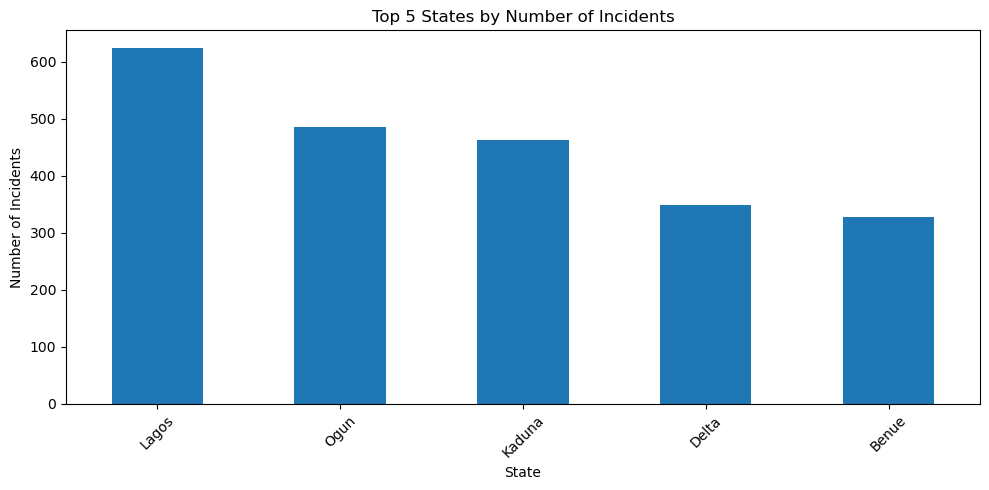

In [19]:


top_5_states.plot(kind="bar", figsize=(10, 5))

plt.title("Top 5 States by Number of Incidents")
plt.xlabel("State")
plt.ylabel("Number of Incidents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
# Total deaths by state
deaths_by_state = df.groupby("State")["Number of deaths"].sum()

# Sort from highest to lowest
deaths_by_state = deaths_by_state.sort_values(ascending=False)

# Display the top 10 states
print(deaths_by_state.head(10))

State
Borno      5719
Kaduna     2577
Zamfara    2531
Niger      2454
Benue      2089
Katsina    2053
Plateau    1500
Lagos      1056
Ogun        978
Anambra     897
Name: Number of deaths, dtype: int64


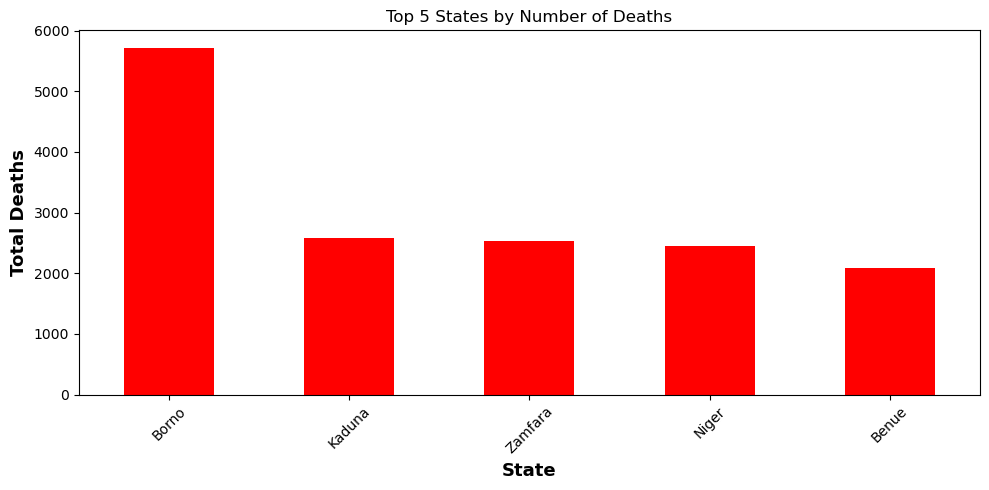

In [21]:
top_5_deaths = deaths_by_state.head(5)

top_5_deaths.plot(kind="bar", figsize=(10, 5), color="red")

plt.title("Top 5 States by Number of Deaths")
plt.xlabel("State", fontweight="bold",fontsize=13)
plt.ylabel("Total Deaths",fontweight="bold",fontsize=13)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
incidents_by_year = df["Year"].value_counts().sort_index()

print(incidents_by_year)

Year
2022.0    1656
2023.0    2613
2024.0    2613
2025.0     617
Name: count, dtype: int64


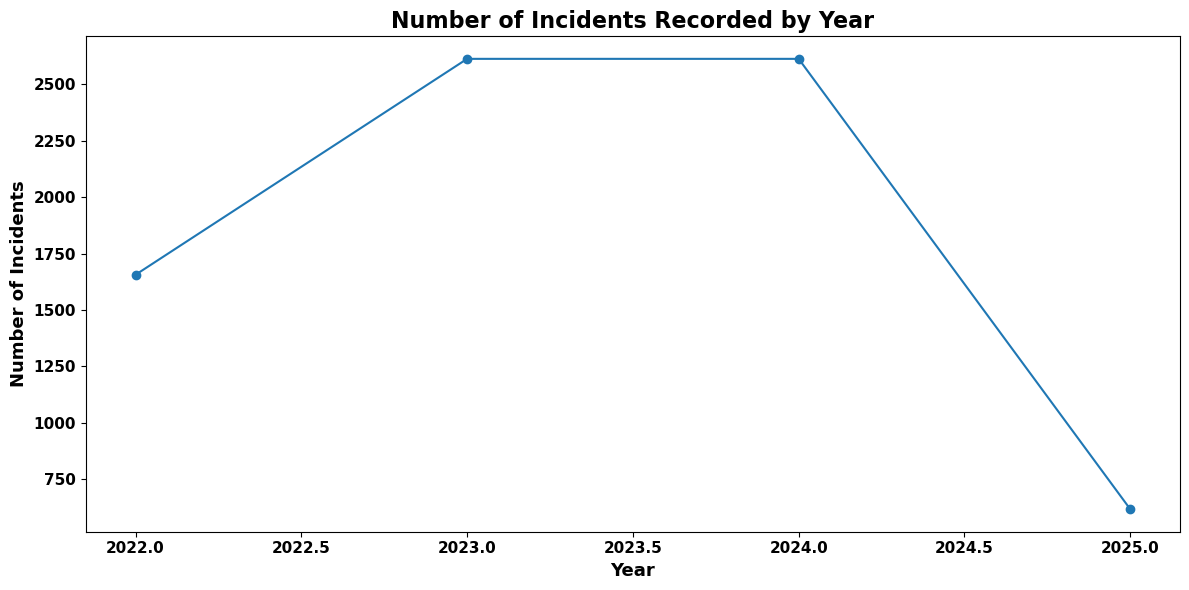

In [23]:
incidents_by_year.plot(kind="line", figsize=(12, 6), marker="o")

plt.title("Number of Incidents Recorded by Year",
          fontsize=16, fontweight="bold")

plt.xlabel("Year", fontsize=13, fontweight="bold")
plt.ylabel("Number of Incidents", fontsize=13, fontweight="bold")

plt.xticks(fontsize=11, fontweight="bold")
plt.yticks(fontsize=11, fontweight="bold")


plt.tight_layout()
plt.show()

In [24]:
most_deaths = df.loc[df["Number of deaths"].idxmax()]

print(most_deaths)


Identifier                       IBD026788
Title               Herdsmen Attack, Benue
Start date             2023-02-27 00:00:00
End date               2023-03-07 00:00:00
Number of deaths                       244
Year                                2023.0
Month                                March
State                                Benue
Name: 5433, dtype: object


In [25]:
incidents_by_year = df["Year"].value_counts().sort_index()

print(incidents_by_year)

Year
2022.0    1656
2023.0    2613
2024.0    2613
2025.0     617
Name: count, dtype: int64


In [26]:
deaths_by_year = df.groupby("Year")["Number of deaths"].sum()

print(deaths_by_year)

Year
2022.0     8386
2023.0    11922
2024.0    12238
2025.0     2806
Name: Number of deaths, dtype: int64


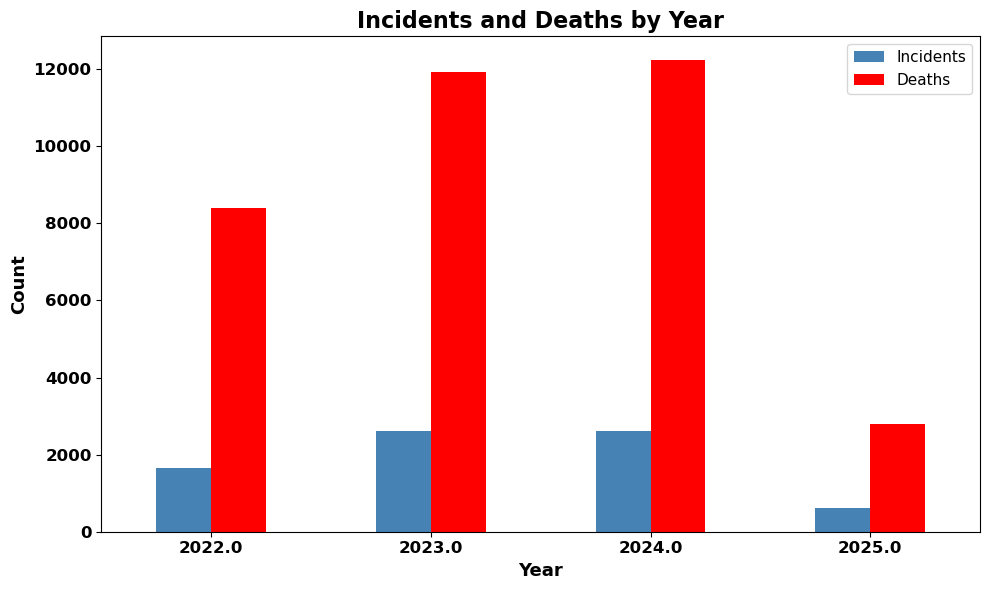

In [27]:
year_comparison = pd.DataFrame({
    "Incidents": incidents_by_year,
    "Deaths": deaths_by_year
})

year_comparison.plot(
    kind="bar",
    figsize=(10, 6),color=["steelblue", "red"]
)

plt.title(
    "Incidents and Deaths by Year",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=13, fontweight="bold")
plt.ylabel("Count", fontsize=13, fontweight="bold")

plt.xticks(rotation=0, fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [28]:
incidents_by_month = df["Month"].value_counts().sort_index()

print(incidents_by_month)

Month
April        543
August       737
December     560
February     555
January      661
July         684
June         575
March        661
May          472
November     635
October      691
September    725
Name: count, dtype: int64


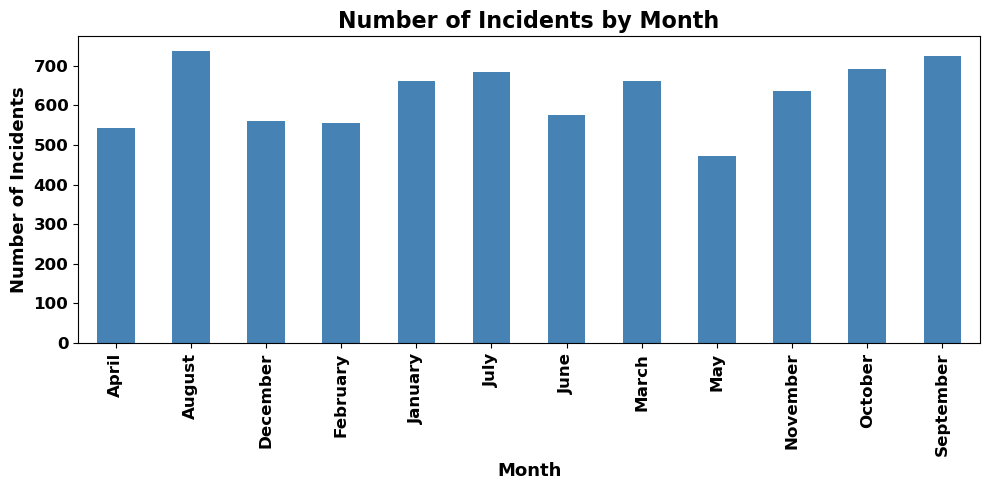

In [29]:
incidents_by_month.plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue"
)

plt.title(
    "Number of Incidents by Month",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month", fontsize=13, fontweight="bold")
plt.ylabel("Number of Incidents", fontsize=13, fontweight="bold")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

In [30]:
monthly_deaths = df.groupby('Month')['Number of deaths'].sum()
monthly_deaths

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_deaths = monthly_deaths.reindex(month_order)
monthly_deaths

Month
January      3376
February     2291
March        3094
April        2607
May          2415
June         2728
July         2522
August       2943
September    3601
October      3673
November     3421
December     2681
Name: Number of deaths, dtype: int64

In [31]:
state_deaths = df.groupby('State')['Number of deaths'].sum().sort_values(ascending=False)

state_deaths.idxmax(), state_deaths.max()
state_deaths.head(10)

State
Borno      5719
Kaduna     2577
Zamfara    2531
Niger      2454
Benue      2089
Katsina    2053
Plateau    1500
Lagos      1056
Ogun        978
Anambra     897
Name: Number of deaths, dtype: int64

In [32]:
df['Title'].value_counts().head(10)

Title
Auto Crash, Ogun             203
Auto Crash, Lagos            144
Banditry, Kaduna              78
Herdsmen Attack, Benue        61
Banditry, Katsina             54
Auto Crash, Niger             53
Auto Crash, FCT (Abuja)       52
Army vs Boko Haram, Borno     51
Banditry, Zamfara             51
Army vs Bandits, Kaduna       50
Name: count, dtype: int64

In [33]:
incident_deaths = (
    df.groupby('Title')['Number of deaths']
    .sum()
    .sort_values(ascending=False)
)

incident_deaths.head(10)

Title
Army vs Boko Haram, Borno     1143
Herdsmen Attack, Benue         789
Banditry, Katsina              774
Banditry, Zamfara              714
Auto Crash, Ogun               567
Boko Haram vs ISWAP, Borno     524
Gunmen Attack, Plateau         448
Auto Crash, Niger              430
NAF vs Boko Haram, Borno       395
ISWAP vs Boko Haram, Borno     377
Name: Number of deaths, dtype: int64

In [34]:
year_state_deaths = pd.pivot_table(
    df,
    values='Number of deaths',
    index='State',
    columns='Year',
    aggfunc='sum',
    fill_value=0
)

year_state_deaths.head(10)

Year,2022.0,2023.0,2024.0,2025.0
State,,,,
,2,0,7,0
( Abuja),2,0,0,0
(Abuja),5,0,0,0
ANambra,0,3,0,0
Abia,91,174,170,33
Abuja,1,1,5,0
Abuja (FCT),0,4,0,0
Adamawa,105,88,266,44
Air Force vs Bandits,9,0,0,0


In [35]:
top_states = (
    df.groupby('State')['Number of deaths']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_states

State
Borno      5719
Kaduna     2577
Zamfara    2531
Niger      2454
Benue      2089
Katsina    2053
Plateau    1500
Lagos      1056
Ogun        978
Anambra     897
Name: Number of deaths, dtype: int64

In [36]:
incident_by_state = df.groupby('State').size()

In [37]:
deaths_by_state = df.groupby('State')['Number of deaths'].sum()

In [38]:
state_analysis = pd.DataFrame({
    'Number_of_Incidents': incident_by_state,
    'Total_Deaths': deaths_by_state
})

state_analysis = state_analysis.sort_values(
    'Total_Deaths',
    ascending=False
)

state_analysis.head(10)

,Number_of_Incidents,Total_Deaths
State,,
Borno,315,5719
Kaduna,462,2577
Zamfara,204,2531
Niger,325,2454
Benue,327,2089
Katsina,226,2053
Plateau,269,1500
Lagos,624,1056
Ogun,485,978


In [39]:
state_analysis['Average_Deaths_Per_Incident'] = (
    state_analysis['Total_Deaths'] /
    state_analysis['Number_of_Incidents']
)

state_analysis.head(10)

,Number_of_Incidents,Total_Deaths,Average_Deaths_Per_Incident
State,,,
Borno,315,5719,18.155556
Kaduna,462,2577,5.577922
Zamfara,204,2531,12.406863
Niger,325,2454,7.550769
Benue,327,2089,6.388379
Katsina,226,2053,9.084071
Plateau,269,1500,5.576208
Lagos,624,1056,1.692308
Ogun,485,978,2.016495


In [40]:
state_analysis['Average_Deaths_Per_Incident'].idxmax()

'Bornon'

In [41]:
df[['Title', 'State', 'Start date', 'Number of deaths']].sort_values(
    'Number of deaths',
    ascending=False
).head(10)

,Title,State,Start date,Number of deaths
5433,"Herdsmen Attack, Benue",Benue,2023-02-27,244
2317,"Heat Waves, Adamawa",Adamawa,2024-05-01,210
5438,"ISWAP vs Boko Haram, Borno",Borno,2023-02-26,200
2817,"Banditry, Katsina",Katsina,2024-03-04,200
6859,"Army vs Boko Haram, Borno",Borno,2022-08-30,200
1046,"Petrol Tanker Explosion, Jigawa",Jigawa,2024-10-15,186
1146,"Boat Mishap, Niger",Niger,2024-10-01,180
2223,"Banditry, Zamfara",Zamfara,2024-05-13,150
5940,"Banditry, Zamfara",Zamfara,2022-12-18,130
3396,"Army Bombs Villagers, Kaduna",Kaduna,2023-12-03,127


In [42]:
df.shape

(7500, 8)

In [43]:
df.isnull().sum()

Identifier          0
Title               0
Start date          1
End date            1
Number of deaths    0
Year                1
Month               1
State               0
dtype: int64

In [44]:
df.dtypes

Identifier                  object
Title                       object
Start date          datetime64[ns]
End date            datetime64[ns]
Number of deaths             int64
Year                       float64
Month                       object
State                       object
dtype: object

In [45]:
from collections import Counter
import re

text = " ".join(df["Title"].dropna()).lower()

words = re.findall(r'\b[a-z]+\b', text)

word_counts = Counter(words)

print(word_counts.most_common(15))

[('vs', 2686), ('crash', 1054), ('auto', 1050), ('gunmen', 729), ('lagos', 624), ('man', 564), ('attack', 497), ('police', 494), ('bandits', 493), ('ogun', 485), ('kaduna', 463), ('kill', 448), ('delta', 353), ('benue', 328), ('army', 327)]


In [46]:
incident_keywords = [
    "attack",
    "crash",
    "fire",
    "accident",
    "kill",
    "killed",
    "kidnap",
    "kidnapping",
    "robbery",
    "flood",
    "drowning","auto","gunmen","police","bandits",
    "explosion"
]

keyword_counts = {}

for keyword in incident_keywords:
    keyword_counts[keyword] = df["Title"].str.lower().str.contains(
        keyword, na=False
    ).sum()

keyword_counts = pd.Series(keyword_counts).sort_values(ascending=False)

print(keyword_counts)

crash         1056
auto          1050
kill           861
gunmen         729
police         583
attack         503
bandits        493
kidnap         385
flood          189
explosion       75
killed          53
accident        20
fire            17
robbery         17
kidnapping       2
drowning         1
dtype: int64


In [ ]:
useful_keywords = keyword_counts[
    ["crash", "auto", "gunmen", "attack", "police", "bandits", "kill"]
]

useful_keywords.plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue"
)

plt.title(
    "Common Incident Keywords in Titles",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Incident Keyword", fontsize=13, fontweight="bold")
plt.ylabel("Number of Occurrences", fontsize=13, fontweight="bold")

plt.xticks(rotation=45, fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

In [ ]:
df = df[
    [
        "Identifier",
        "Title",
        "Start date",
        "End date",
        "Number of deaths",
        "Year",
        "Month",
        "State"
    ]
]

df.head()

In [ ]:
df.dtypes

In [50]:
df.to_csv("cleaned incidents.csv", index=False)
